#### Further analysis of the three-chamber system with multiple potential outputs

Three-chamber system in a "V" layout

Run simulations in parallel using parallel_V_formation.py`, which then saves to disk as `fine_output.npz`. Analysis proceeds after loading in the npz.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import scipy
import scipy.stats

import cnetwork
from cnetwork import MagmaChamber, GlobalSystemThreshold

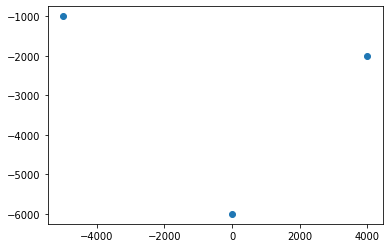

In [2]:
# Set reference density of melt
rhoref = 2500
# Set limits of characteristic size of chamber
R_ref = 1000
# Uniformly randomly distribution volume
V_ref = (4/3)*np.pi*R_ref**3

# Generate list of chambers
x_nodes = np.array([0,     -5000,  4000,])
y_nodes = np.array([0,     -0,     0,])
z_nodes = np.array([-6000, -1000,  -2000,])
V_nodes = np.array([4.0,    0.25,  1 ]) * V_ref
list_nodes = [MagmaChamber(x=x, y=y, z=z,
  p_setting=None, vref=1.0/rhoref,
  T_setting=1000+273.15, V_setting=V)
  for (x,y,z,V) in zip(x_nodes, y_nodes, z_nodes, V_nodes)]
plt.scatter(x_nodes, z_nodes)

In [7]:
import parallel_V_formation
import os

if os.path.isfile("output_V2.npz"):
  print("Output is present. Skipping simulation.")
else:
  print("Starting parallel runs. (est. 1.5hr on 12x threads).")
  parallel_V_formation.run_parallel()

Starting parallel runs. (est. 3hr on 12x threads).


### Sample parameter space in parallel

In [ ]:
# Save format
# m_eruption_by_chamber=export_m_eruption_by_chamber,
# m=export_m,
# p=export_p,
# # u=export_u,
# mg_rates=mg_rates,
# mg_contrast=mg_contrast,
# t_vec=t_vec,
# )

In [507]:
# Load to memory
blob = np.load("output_V2.npz")
m_eruption_by_chamber = blob["m_eruption_by_chamber"]
# m = blob["m"]
p = blob["p"]
# u = blob["u"]
mg_rates = blob["mg_rates"]
mg_contrast = blob["mg_contrast"]
# Static t_vec for fine_output.npz
t_vec = np.linspace(0, 20e7, 100000)

In [508]:
# Compute dependent quantities
dt = (t_vec[1] - t_vec[0])
t_total = (t_vec[-1] - t_vec[0])
max_rates = mg_rates * V_ref * rhoref
# Time-integration of eruption rates
m_eruption_integrated = dt * np.einsum(
  "ijkl -> ijl", m_eruption_by_chamber)
# Compute partition of erupted material with shape (*, *, nchambers)
eruption_partition = m_eruption_integrated / np.sum(
  m_eruption_integrated, axis=2, keepdims=True)
# Compute throughput
#   (maps to intrusive*-extrusive (* of injected mass))
throughput_efficiency = m_eruption_integrated.sum(axis=2) / (t_total * max_rates)

In [509]:
# plt.rcParams["font.family"] = "sans-serif" # Default
# plt.rcParams["font.family"] = "arial" # Poster option

C:\Users\Fredric\AppData\Local\Temp\ipykernel_40088\1917996535.py:94: MatplotlibDeprecationWarning: shading='flat' when X and Y have the same dimensions as C is deprecated since 3.3.  Either specify the corners of the quadrilaterals with X and Y, or pass shading='auto', 'nearest' or 'gouraud', or set rcParams['pcolor.shading'].  This will become an error two minor releases later.
  cf = axes["contour1"].pcolormesh(1/mg_contrast, (mg_rates) * 3.1536e+7, 1 - eruption_partition[:,:,1],
C:\Users\Fredric\AppData\Local\Temp\ipykernel_40088\1917996535.py:162: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


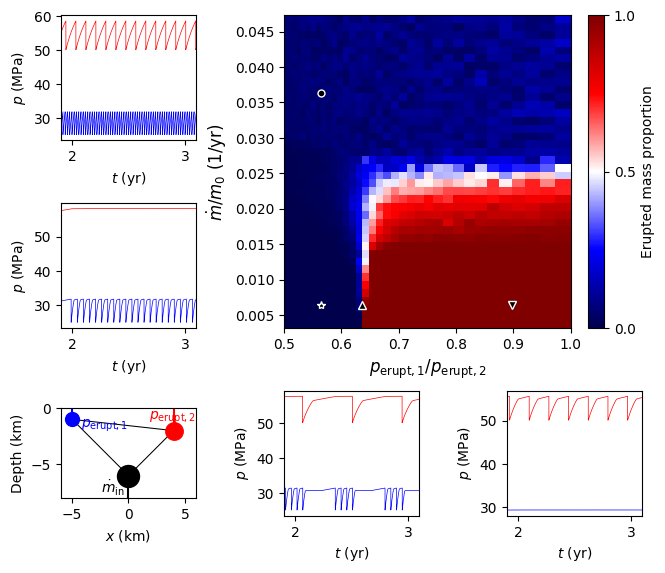

In [535]:
# fig, ax = plt.subplots(figsize=(6, 9), dpi=100)
# gridspec = fig.add_gridspec(3, 3, width_ratios=[1, 1, 1],
#     height_ratios=[1, 2.2, 2.2])

layout1 = [
    ['A', 'B', 'C',],
    ['D', 'D', 'F',],
    ['E', 'E', 'E',],
]
layout2 = [
    ['schematic', 'schematic'],
    ['t1', 'contour1',],
    ['t2', 'contour1',],
    ['t3', 'contour2',],
    ['t4', 'contour2',],
]
layout3 = [
    ['t1', 'contour1', 'contour1'],
    ['t2', 'contour1', 'contour1'],
    ['schematic', 't3', 't4'],
]

layout = layout3
if layout == layout1:
  fig, axes = plt.subplot_mosaic(
    layout,
    figsize=(6.5, 9.5),
    gridspec_kw={
      'height_ratios': [1.0, 2.2, 2.2],
      # 'wspace': 0.65,
      # 'hspace': 0.4,
    },
    dpi=100,
  )
elif layout == layout2:
  fig, axes = plt.subplot_mosaic(
      layout,
      figsize=(7.5, 9.5),
      gridspec_kw={
        'height_ratios': [0.5, 0.5, 0.5, 0.5, 0.5],
        'width_ratios': [0.4, 0.5],
        # 'wspace': 0.65,
        # 'hspace': 0.4,
      },
      dpi=100,
    )
else:
  fig, axes = plt.subplot_mosaic(
    layout,
    figsize=(7.5, 6.5),
    gridspec_kw={
      'height_ratios': [0.5, 0.5, 0.5],
      'width_ratios': [0.5, 0.5, 0.5],
      'wspace': 0.65,
      'hspace': 0.5,
    },
    dpi=100,
  )

node_sizes = (V_nodes / V_nodes.max())**(1.0/3.0) * 250

axes["schematic"].scatter(x_nodes[0]/1e3, z_nodes[0]/1e3, c='k', s=node_sizes[0])
axes["schematic"].scatter(x_nodes[1]/1e3, z_nodes[1]/1e3, c='b', s=node_sizes[1])
axes["schematic"].scatter(x_nodes[2]/1e3, z_nodes[2]/1e3, c='r', s=node_sizes[2])

# Eruption edges
axes["schematic"].plot([x_nodes[1]/1e3, x_nodes[1]/1e3],
         [z_nodes[1]/1e3, 0.0], 'b')
axes["schematic"].plot([x_nodes[2]/1e3, x_nodes[2]/1e3],
         [z_nodes[2]/1e3, 0.0], 'r')
# Inlet edge
axes["schematic"].plot([x_nodes[0]/1e3, x_nodes[0]/1e3],
         [-8, z_nodes[0]/1e3], 'k')

# Edges between nodes
axes["schematic"].plot([x_nodes[0]/1e3, x_nodes[1]/1e3],
         [z_nodes[0]/1e3, z_nodes[1]/1e3], 'k', zorder=-1, linewidth=0.75)
axes["schematic"].plot([x_nodes[0]/1e3, x_nodes[2]/1e3],
         [z_nodes[0]/1e3, z_nodes[2]/1e3], 'k', zorder=-1, linewidth=0.75)
axes["schematic"].plot([x_nodes[2]/1e3, x_nodes[1]/1e3],
         [z_nodes[2]/1e3, z_nodes[1]/1e3], 'k', zorder=-1, linewidth=0.75)

axes["schematic"].text(-2.4, -7.55, "$\dot{m}_\mathrm{in}$", color='k')
axes["schematic"].text(-4.2, -1.75, "$p_{\mathrm{erupt},1}$", color='b')
axes["schematic"].text(1.8, -1.0, "$p_{\mathrm{erupt},2}$", color='r')
axes["schematic"].set_xlim(-6, 6)
axes["schematic"].set_ylim(-8, 0)
axes["schematic"].set_xlabel("$x$ (km)", fontsize=10)
axes["schematic"].set_ylabel("Depth (km)", fontsize=10)
axes["schematic"].set_aspect(1.0)

# Plot indicator for eruption from chamber #1 (when eruption_partition[:, :, 1]
# is zero, only chamber #2 erupts)
cf = axes["contour1"].pcolormesh(1/mg_contrast, (mg_rates) * 3.1536e+7, 1 - eruption_partition[:,:,1],
  # levels=np.linspace(0, 1, 100),
  cmap=matplotlib.pyplot.cm.seismic)
axes["contour1"].set_xlabel("$p_{\mathrm{erupt},1} / p_{\mathrm{erupt},2}$", fontsize=12)
# plt.ylabel("Mass turnover rate: lowest node (1/s)")
# plt.ylabel("Mass turnover rate (yr${}^{-1}$)", fontsize=14)
axes["contour1"].set_ylabel("$\dot{m} / m_0$ (1/yr)", fontsize=12)
plt.sca(axes["contour1"])
cb = plt.colorbar(cf, label="Erupted mass proportion",
                  # location="bottom",
                  ticks=[0, 0.5, 1.0], ax=axes["contour1"])

''' Subpanel markers '''
ij_A = (27,30)
ij_B = (27,3)
ij_C = (20, 3)
ij_D = (4, 3)
markerA = axes["contour1"].plot(1/mg_contrast[ij_A],
                         3.1536e+7 * mg_rates[ij_A], '.', c='k', markersize=10, markeredgecolor='w', markeredgewidth=1)
markerB = axes["contour1"].plot(1/mg_contrast[ij_B],
                         3.1536e+7 * mg_rates[ij_B], '*', c='k', markeredgecolor='w', markeredgewidth=1)
markerC = axes["contour1"].plot(1/mg_contrast[ij_C],
                         3.1536e+7 * mg_rates[ij_C], '^', c='k', markeredgecolor='w', markeredgewidth=1)
markerD = axes["contour1"].plot(1/mg_contrast[ij_D],
                         3.1536e+7 * mg_rates[ij_D], 'v', c='k', markeredgecolor='w', markeredgewidth=1)

imin = 28000
imax = 50000
axes["t1"].plot(t_vec[imin:imax]/ 3.1536e+7,
               (p[ij_A][imin:imax,1] - 0*p[ij_A][0,1]) / 1e6, 'b', linewidth=0.5)
axes["t1"].plot(t_vec[imin:imax]/ 3.1536e+7,
               (p[ij_A][imin:imax,2] - 0*p[ij_A][0,2]) / 1e6, 'r', linewidth=0.5)

axes["t2"].plot(t_vec[imin:imax]/ 3.1536e+7,
               (p[ij_B][imin:imax,1] - 0*p[ij_B][0,1]) / 1e6, 'b', linewidth=0.5)
axes["t2"].plot(t_vec[imin:imax]/ 3.1536e+7,
               (p[ij_B][imin:imax,2] - 0*p[ij_B][0,2]) / 1e6, 'r', linewidth=0.5)

axes["t3"].plot(t_vec[imin:imax]/ 3.1536e+7,
               (p[ij_C][imin:imax,1] - 0*p[ij_C][0,1]) / 1e6, 'b', linewidth=0.5)
axes["t3"].plot(t_vec[imin:imax]/ 3.1536e+7,
               (p[ij_C][imin:imax,2] - 0*p[ij_C][0,2]) / 1e6, 'r', linewidth=0.5)

axes["t4"].plot(t_vec[imin:imax]/ 3.1536e+7,
               (p[ij_D][imin:imax,1] - 0*p[ij_D][0,1]) / 1e6, 'b', linewidth=0.5)
axes["t4"].plot(t_vec[imin:imax]/ 3.1536e+7,
               (p[ij_D][imin:imax,2] - 0*p[ij_D][0,2]) / 1e6, 'r', linewidth=0.5)


for ax in [axes["t1"], axes["t2"], axes["t3"], axes["t4"]]:
  ax.set_xlabel("$t$ (yr)")
  ax.set_ylabel("$p$ (MPa)")
  ax.set_xticks([2,3])
  ax.set_xlim([1.9,3.1])


# cf = axes["contour2"].pcolormesh(1/mg_contrast, (mg_rates) * 3.1536e+7, 1 - eruption_partition[:,:,1],
#   # levels=np.linspace(0, 1, 100),
#   cmap=matplotlib.pyplot.cm.seismic)
# axes["contour2"].set_xlabel("$p_{\mathrm{erupt},1} / p_{\mathrm{erupt},2}$", fontsize=14)
# # plt.ylabel("Mass turnover rate: lowest node (1/s)")
# # plt.ylabel("Mass turnover rate (yr${}^{-1}$)", fontsize=14)
# axes["contour2"].set_ylabel("$\dot{m} / m_0$ (1/yr)", fontsize=14)
# plt.sca(axes["contour2"])
# cb = plt.colorbar(cf, label="Erupted mass proportion",
#                   # location="bottom",
#                   ticks=[0, 0.5, 1.0], ax=axes["contour2"])

plt.tight_layout()

plt.savefig("fig_V_main2.png", dpi=200)
plt.savefig("fig_V_main2.eps")
plt.savefig("fig_V_main2.svg")

#### Single figure: layout only

Text(0, 0.5, 'Depth (km)')

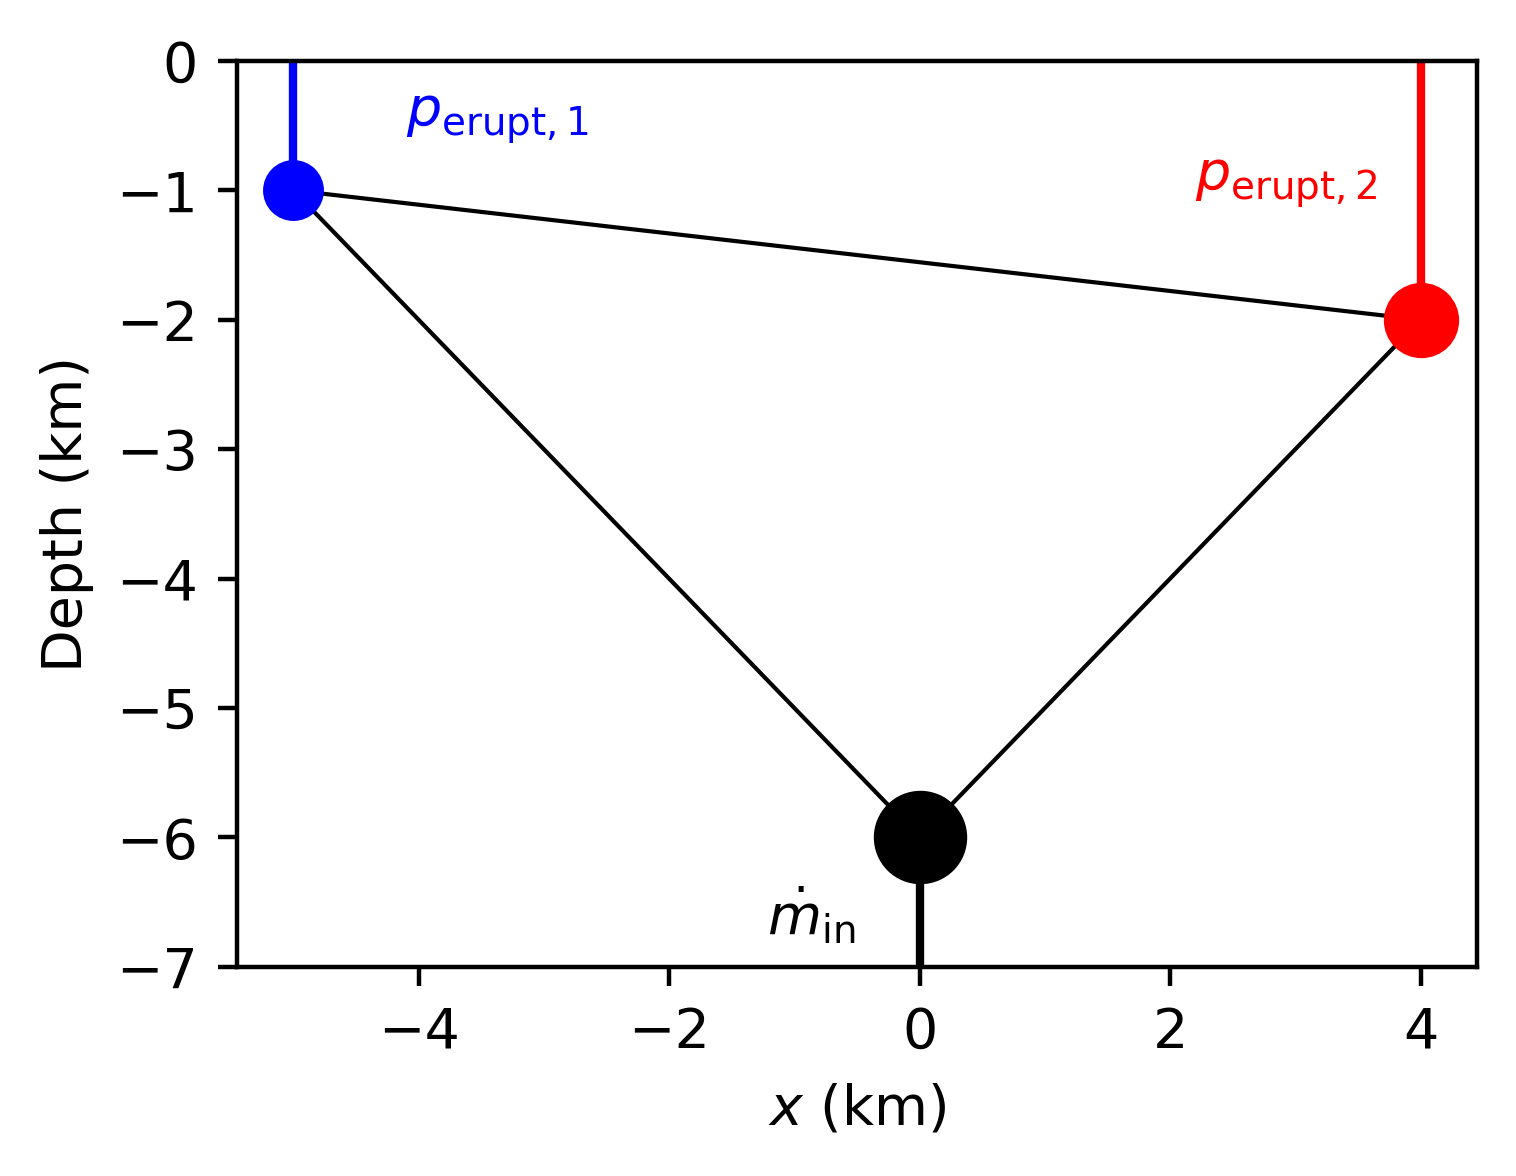

In [50]:
plt.figure(figsize=(4,3), dpi=400)

node_sizes = (V_nodes / V_nodes.max())**(1.0/3.0) * 250

plt.scatter(x_nodes[0]/1e3, z_nodes[0]/1e3, c='k', s=node_sizes[0])
plt.scatter(x_nodes[1]/1e3, z_nodes[1]/1e3, c='b', s=node_sizes[1])
plt.scatter(x_nodes[2]/1e3, z_nodes[2]/1e3, c='r', s=node_sizes[2])

plt.plot([x_nodes[1]/1e3, x_nodes[1]/1e3],
         [z_nodes[1]/1e3, 0.0], 'b')
plt.plot([x_nodes[2]/1e3, x_nodes[2]/1e3],
         [z_nodes[2]/1e3, 0.0], 'r')
plt.plot([x_nodes[0]/1e3, x_nodes[0]/1e3],
         [-7, z_nodes[0]/1e3], 'k')

plt.plot([x_nodes[0]/1e3, x_nodes[1]/1e3],
         [z_nodes[0]/1e3, z_nodes[1]/1e3], 'k', zorder=-1, linewidth=0.75)
plt.plot([x_nodes[0]/1e3, x_nodes[2]/1e3],
         [z_nodes[0]/1e3, z_nodes[2]/1e3], 'k', zorder=-1, linewidth=0.75)
plt.plot([x_nodes[2]/1e3, x_nodes[1]/1e3],
         [z_nodes[2]/1e3, z_nodes[1]/1e3], 'k', zorder=-1, linewidth=0.75)

plt.text(-1.22, -6.75, "$\dot{m}_\mathrm{in}$", color='k')
plt.text(-4.1, -0.5, "$p_{\mathrm{erupt},1}$", color='b')
plt.text(2.2, -1.0, "$p_{\mathrm{erupt},2}$", color='r')
plt.ylim(-7.0, 0)
plt.xlabel("$x$ (km)")
plt.ylabel("Depth (km)")

Text(0, 0.5, 'Inter-eruption period (years)')

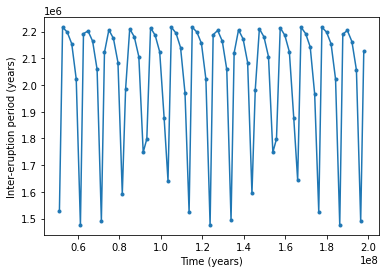

In [232]:
''' Eruption peak picking '''

def pick_peaks(m_erupted_by_chamber, t_vec):
  # Select indices where the total mass m(t) increments
  peak_indices = np.where(np.diff(m_erupted_by_chamber) > 0)[0] + 1
  # Return t at those indices (t_peak)
  return t_vec[peak_indices]

def process_t_IET(t_vec, t_peak):
  # Average over second half of simulation (assume ~"steady state")
  # t_start = t_vec[t_vec.size//2]
  t_start = t_vec[t_vec.size//4]
  t_peak_steady_state = t_peak[np.where(t_peak >= t_start)]
  return t_peak_steady_state[:-1], np.diff(t_peak_steady_state)

def mean_stdev(X):
  return X.mean(), np.std(X)

seconds_per_year = 365 * 24 * 3600
t_peak = pick_peaks(m_eruption_by_chamber[5,14,:,1], t_vec)

t_peak_trim, t_IET_trim = process_t_IET(t_vec, t_peak)

# plt.plot(t_peak[:-1] / seconds_per_year,
#          average_IET(t_vec, t_peak) / seconds_per_year, '.')

# mean_stdev(average_IET(t_vec / seconds_per_year, t_peak / seconds_per_year))

plt.plot(t_peak_trim, t_IET_trim, '.-')
plt.xlabel("Time (years)")
plt.ylabel("Inter-eruption period (years)")

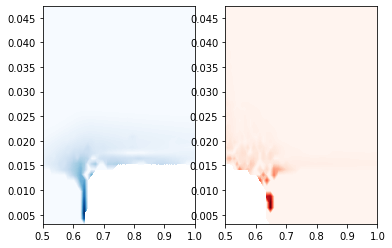

In [250]:
''' Compute mean/stdev of inter-eruption times '''

means_chamber1 = np.full(m_eruption_by_chamber.shape[:2], np.nan)
means_chamber2 = np.full(m_eruption_by_chamber.shape[:2], np.nan)
stdev_chamber1 = np.full(m_eruption_by_chamber.shape[:2], np.nan)
stdev_chamber2 = np.full(m_eruption_by_chamber.shape[:2], np.nan)

for i in range(m_eruption_by_chamber.shape[0]):
  for j in range(m_eruption_by_chamber.shape[1]):
    t_peak = pick_peaks(m_eruption_by_chamber[i,j,:,1], t_vec)
    t_peak_trim, t_IET_trim = process_t_IET(t_vec, t_peak)
    if len(t_IET_trim) != 0:
      means_chamber1[i,j] = np.mean(t_IET_trim)
      stdev_chamber1[i,j] = np.std(t_IET_trim)

    t_peak = pick_peaks(m_eruption_by_chamber[i,j,:,2], t_vec)
    t_peak_trim, t_IET_trim = process_t_IET(t_vec, t_peak)
    if len(t_IET_trim) != 0:
      means_chamber2[i,j] = np.mean(t_IET_trim)
      stdev_chamber2[i,j] = np.std(t_IET_trim)

plt.subplot(1,2,1)
plt.contourf(1/mg_contrast, (mg_rates) * 3.1536e+7,
             stdev_chamber1, levels=100, cmap=matplotlib.pyplot.cm.Blues)
plt.subplot(1,2,2)
plt.contourf(1/mg_contrast, (mg_rates) * 3.1536e+7,
             stdev_chamber2, levels=100, cmap=matplotlib.pyplot.cm.Reds)

C:\Users\Fredric\AppData\Local\Temp\ipykernel_40088\1051872093.py:24: MatplotlibDeprecationWarning: shading='flat' when X and Y have the same dimensions as C is deprecated since 3.3.  Either specify the corners of the quadrilaterals with X and Y, or pass shading='auto', 'nearest' or 'gouraud', or set rcParams['pcolor.shading'].  This will become an error two minor releases later.
  cf1 = axes["C1"].pcolormesh(
C:\Users\Fredric\AppData\Local\Temp\ipykernel_40088\1051872093.py:30: MatplotlibDeprecationWarning: shading='flat' when X and Y have the same dimensions as C is deprecated since 3.3.  Either specify the corners of the quadrilaterals with X and Y, or pass shading='auto', 'nearest' or 'gouraud', or set rcParams['pcolor.shading'].  This will become an error two minor releases later.
  cf2 = axes["C2"].pcolormesh(
C:\Users\Fredric\AppData\Local\Temp\ipykernel_40088\1051872093.py:36: MatplotlibDeprecationWarning: shading='flat' when X and Y have the same dimensions as C is deprecated 

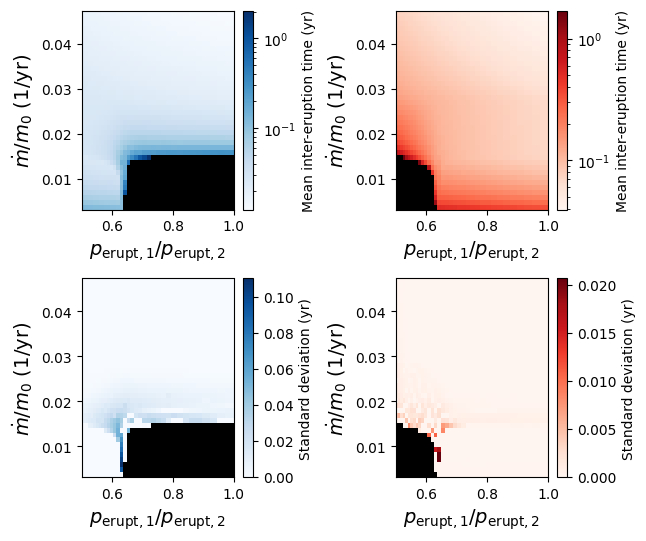

In [505]:
# fig, ax = plt.subplots(figsize=(6, 9), dpi=100)
# gridspec = fig.add_gridspec(3, 3, width_ratios=[1, 1, 1],
#     height_ratios=[1, 2.2, 2.2])

layout = [
    ['C1', 'C2',],
    ['C3', 'C4',],
]

fig, axes = plt.subplot_mosaic(
  layout,
  figsize=(6.5, 5.5),
  gridspec_kw={
    'height_ratios': [1.0, 1.0],
    # 'wspace': 0.65,
    # 'hspace': 0.4,
  },
  dpi=100,
)

plt.style.use("default")
# Plot indicator for eruption from chamber #1 (when eruption_partition[:, :, 1]
# is zero, only chamber #2 erupts)
cf1 = axes["C1"].pcolormesh(
  1/mg_contrast, (mg_rates) * 3.1536e+7,
  (means_chamber1 / seconds_per_year),
  norm=matplotlib.colors.LogNorm(),
  # vmin=0.0, vmax=2.0,
  cmap=matplotlib.pyplot.cm.Blues)
cf2 = axes["C2"].pcolormesh(
  1/mg_contrast, (mg_rates) * 3.1536e+7,
  (means_chamber2 / seconds_per_year),
  norm=matplotlib.colors.LogNorm(),
  # vmin=0.0, vmax=2.0,
  cmap=matplotlib.pyplot.cm.Reds)
cf3 = axes["C3"].pcolormesh(
  1/mg_contrast, (mg_rates) * 3.1536e+7,
  (stdev_chamber1 / seconds_per_year),
  # vmin=0.0, vmax=2.0,
  cmap=matplotlib.pyplot.cm.Blues)
cf4 = axes["C4"].pcolormesh(
  1/mg_contrast, (mg_rates) * 3.1536e+7,
  (stdev_chamber2 / seconds_per_year),
  # vmin=0.0, vmax=2.0,
  cmap=matplotlib.pyplot.cm.Reds)

for ax in [axes["C1"], axes["C2"], axes["C3"], axes["C4"]]:
  ax.set_xlabel("$p_{\mathrm{erupt},1} / p_{\mathrm{erupt},2}$", fontsize=14)
  ax.set_ylabel("$\dot{m} / m_0$ (1/yr)", fontsize=14)
  ax.set_facecolor('black')

cb1 = plt.colorbar(cf1, label="Mean inter-eruption time (yr)",
                  ax=axes["C1"])
cb2 = plt.colorbar(cf2, label="Mean inter-eruption time (yr)",
                  ax=axes["C2"])
cb3 = plt.colorbar(cf3, label="Standard deviation (yr)",
                  ax=axes["C3"])
cb4 = plt.colorbar(cf4, label="Standard deviation (yr)",
                  ax=axes["C4"])

plt.tight_layout()

plt.savefig("fig_appendix_V_IET_statistics.png", dpi=200)
plt.savefig("fig_appendix_V_IET_statistics.eps")
plt.savefig("fig_appendix_V_IET_statistics.svg")

C:\Users\Fredric\AppData\Local\Temp\ipykernel_40088\728542109.py:13: MatplotlibDeprecationWarning: shading='flat' when X and Y have the same dimensions as C is deprecated since 3.3.  Either specify the corners of the quadrilaterals with X and Y, or pass shading='auto', 'nearest' or 'gouraud', or set rcParams['pcolor.shading'].  This will become an error two minor releases later.
  ax.pcolormesh(


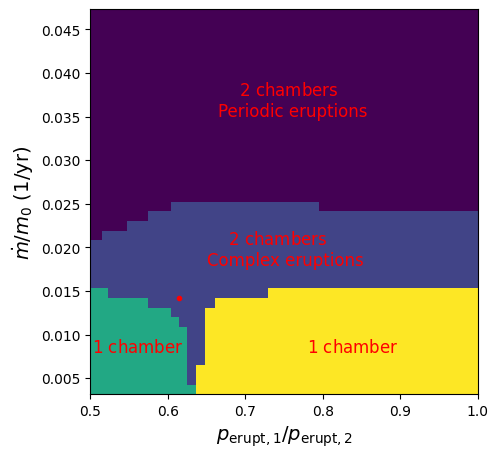

In [504]:
# Regime plot

# Compute contour of stdev / mean > 0.05

statistical_threshold = 0.10

is_nonperiodic = ((stdev_chamber1 / (means_chamber1) > statistical_threshold)
      + (stdev_chamber2 / (means_chamber2) > statistical_threshold))
# Fill True under the farthest contour
is_nonperiodic = is_nonperiodic[:,::-1].cumsum(axis=1)[:,::-1].astype(bool)

fig, ax = plt.subplots(figsize=(5,5), dpi=100)
ax.pcolormesh(
  1/mg_contrast, (mg_rates) * 3.1536e+7,
  # vmin=0.0, vmax=2.0,
  np.isnan(stdev_chamber1) * 4.0
  + np.isnan(stdev_chamber2) * 2.0
  + is_nonperiodic
)

ijtest = (22,10)
ax.plot(
  1/mg_contrast[ijtest],
  (mg_rates[ijtest]) * 3.1536e+7,
  'r.'
)

ax.set_xlabel("$p_{\mathrm{erupt},1} / p_{\mathrm{erupt},2}$", fontsize=14)
ax.set_ylabel("$\dot{m} / m_0$ (1/yr)", fontsize=14)

# ax_inset = ax.inset_axes([0.51, 0.63, 0.44, 0.35])
# ax_inset.plot(t_vec / seconds_per_year, p[ijtest[0],ijtest[1],:,1] / 1e6,
#               color="blue")
# ax_inset.tick_params(axis='both', labelcolor='white')
# ax_inset.set_xlim(0.25, 1.25)
# ax_inset.set_ylabel("$p_1$ (MPa)", color='white')
# ax_inset.set_xlabel("Time (yr)", color='white')

ax.text(0.502, 0.008, "$1$ chamber", color='red', fontsize=12)
ax.text(0.78, 0.008, "$1$ chamber", color='red', fontsize=12)
ax.text(0.65, 0.018, "    $2$ chambers \nComplex eruptions", color='red', fontsize=12)
# ax.text(0.52, 0.035, "    $2$ chambers \nPeriodic eruptions", color='red', fontsize=12)
ax.text(0.665, 0.035, "    $2$ chambers \nPeriodic eruptions", color='red', fontsize=12)

plt.savefig("fig_V_regime.png", dpi=200)
plt.savefig("fig_V_regime.eps")
plt.savefig("fig_V_regime.svg")

Crit. overpressure ratio:  0.7
Turnover rate (1/yr):  0.01529496
Pressure history for a specific case:


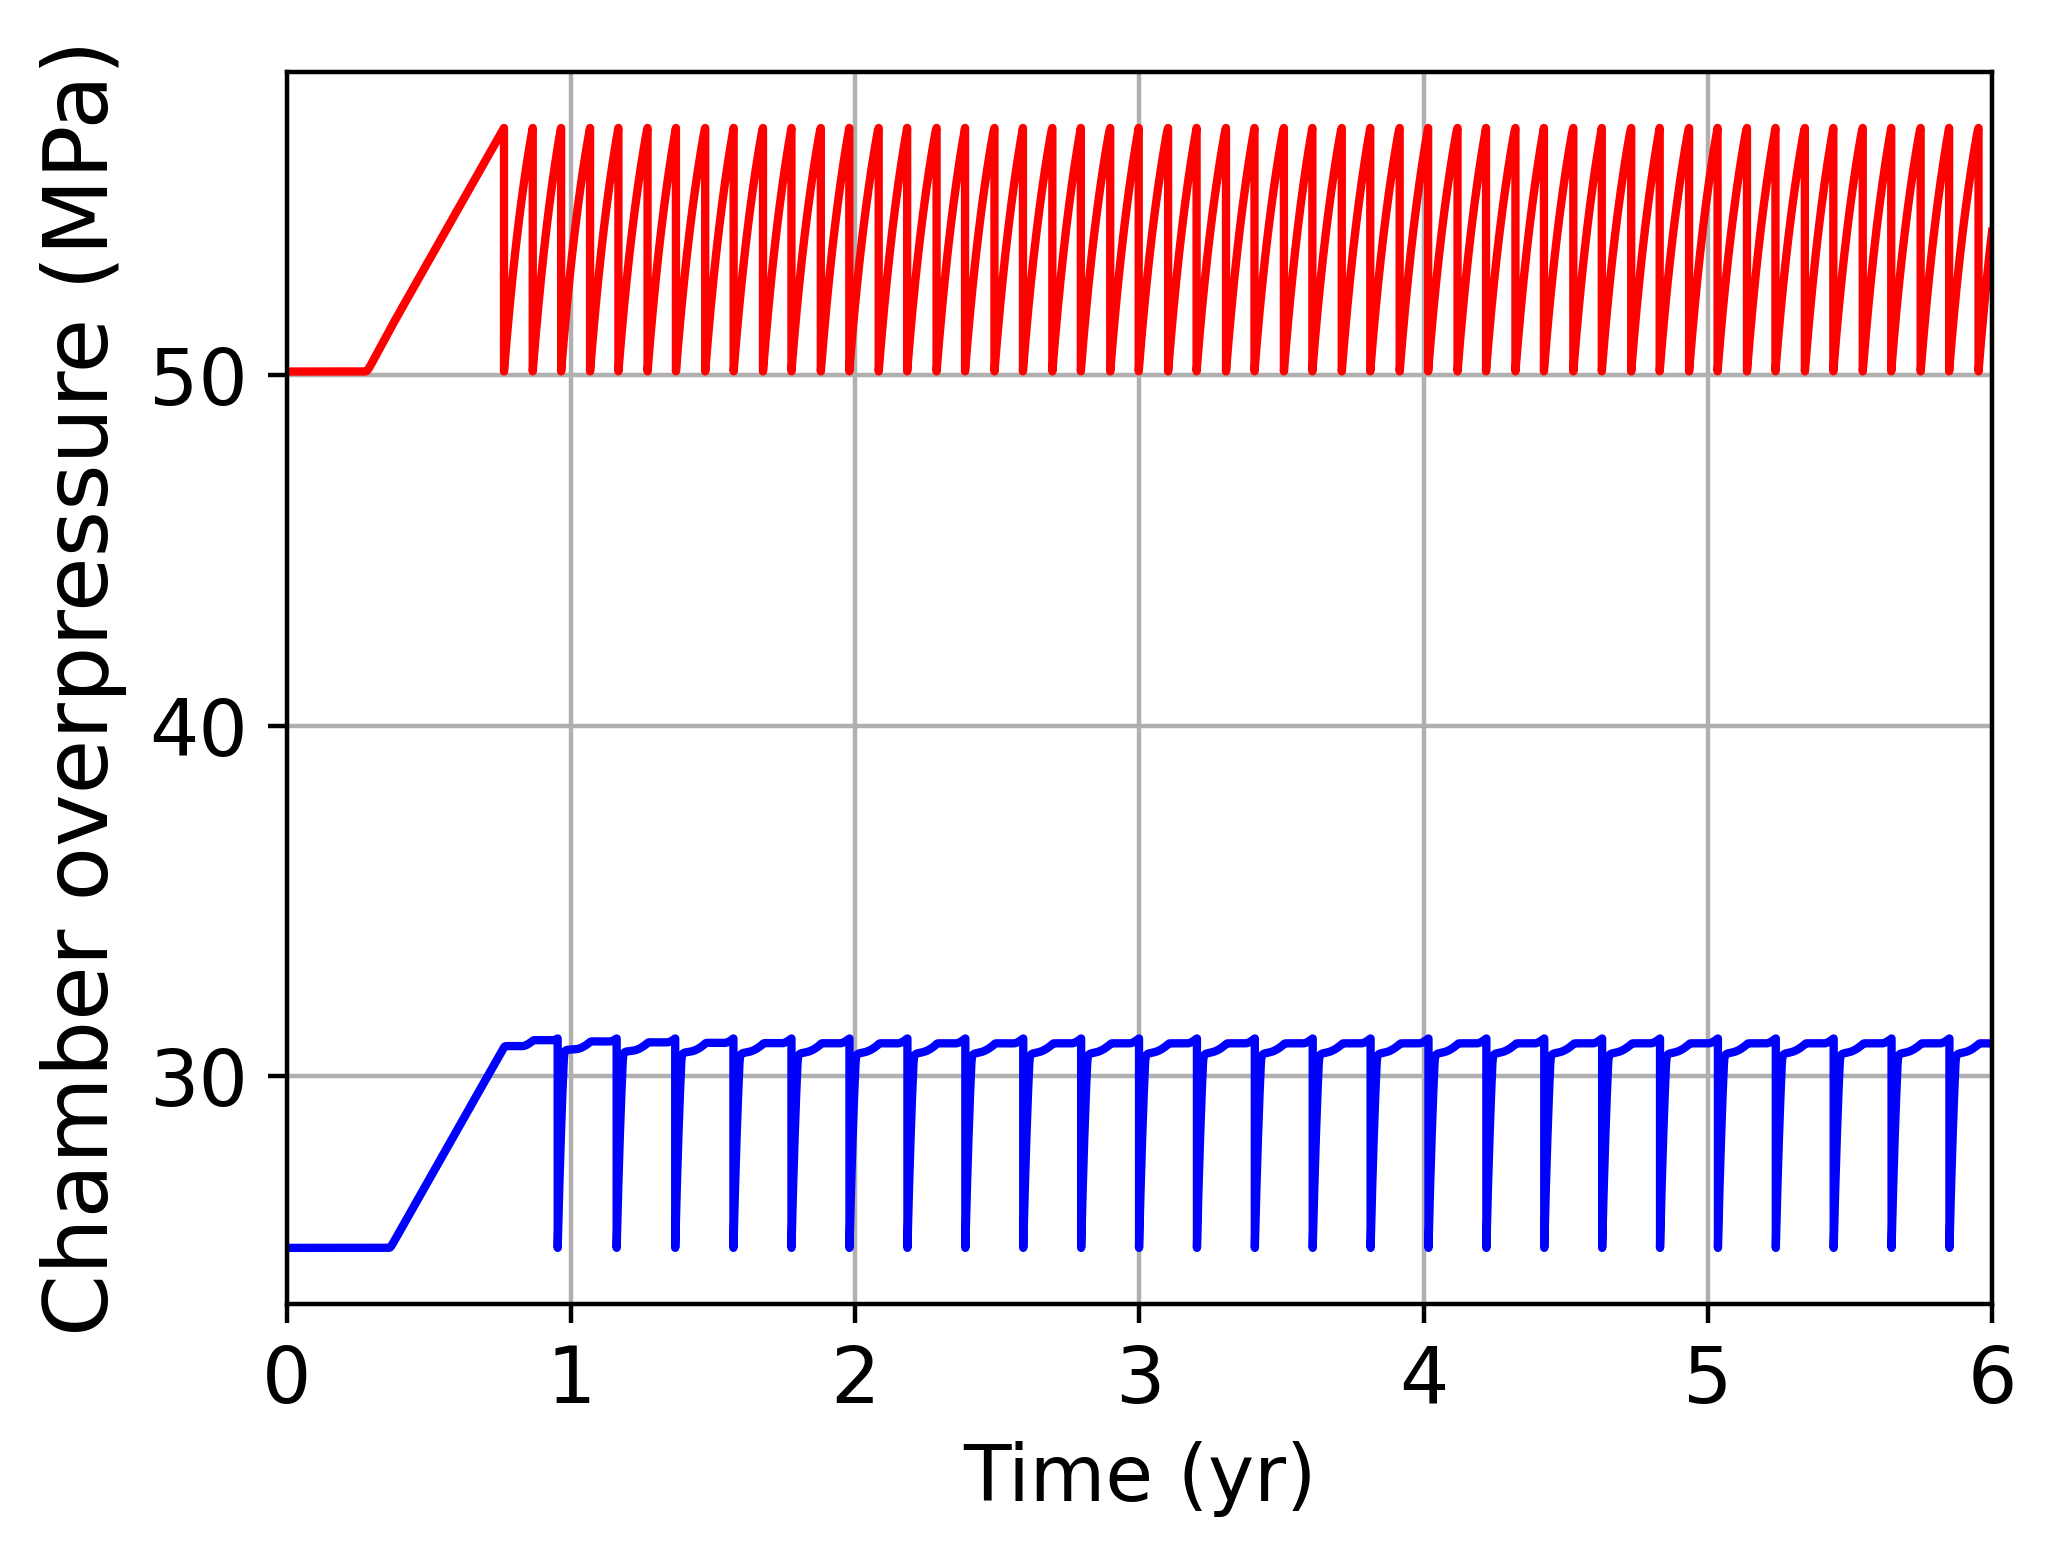

In [422]:
# Select a specific case
i, j = 15, 11
print("Crit. overpressure ratio: ", 1/mg_contrast[i,j])
print("Turnover rate (1/yr): ", mg_rates[i,j] * 3.1536e+7)

# plt.figure(figsize=(8,4))
plt.figure(figsize=(5.5,4), dpi=400)
# plt.subplot(1,2,1)
# plt.plot(t_vec, p[i,j][:,1])
# plt.subplot(1,2,2)
plt.plot(t_vec/ 3.1536e+7, (p[i,j][:,1] - 0*p[i,j][0,1]) / 1e6, 'b', linewidth=1.5)
plt.plot(t_vec/ 3.1536e+7, (p[i,j][:,2] - 0*p[i,j][0,2]) / 1e6, 'r', linewidth=1.5)
plt.tick_params(axis="both", labelsize=14)
plt.xlabel("Time (yr)", fontsize=14)
plt.xlim(0, 6)
plt.ylabel("Chamber overpressure (MPa)", fontsize=16)
plt.grid(which="both")
print("Pressure history for a specific case:")

Crit. overpressure ratio:  0.6603773584905661
Turnover rate (1/yr):  0.009776159999999999
Pressure history for a specific case:


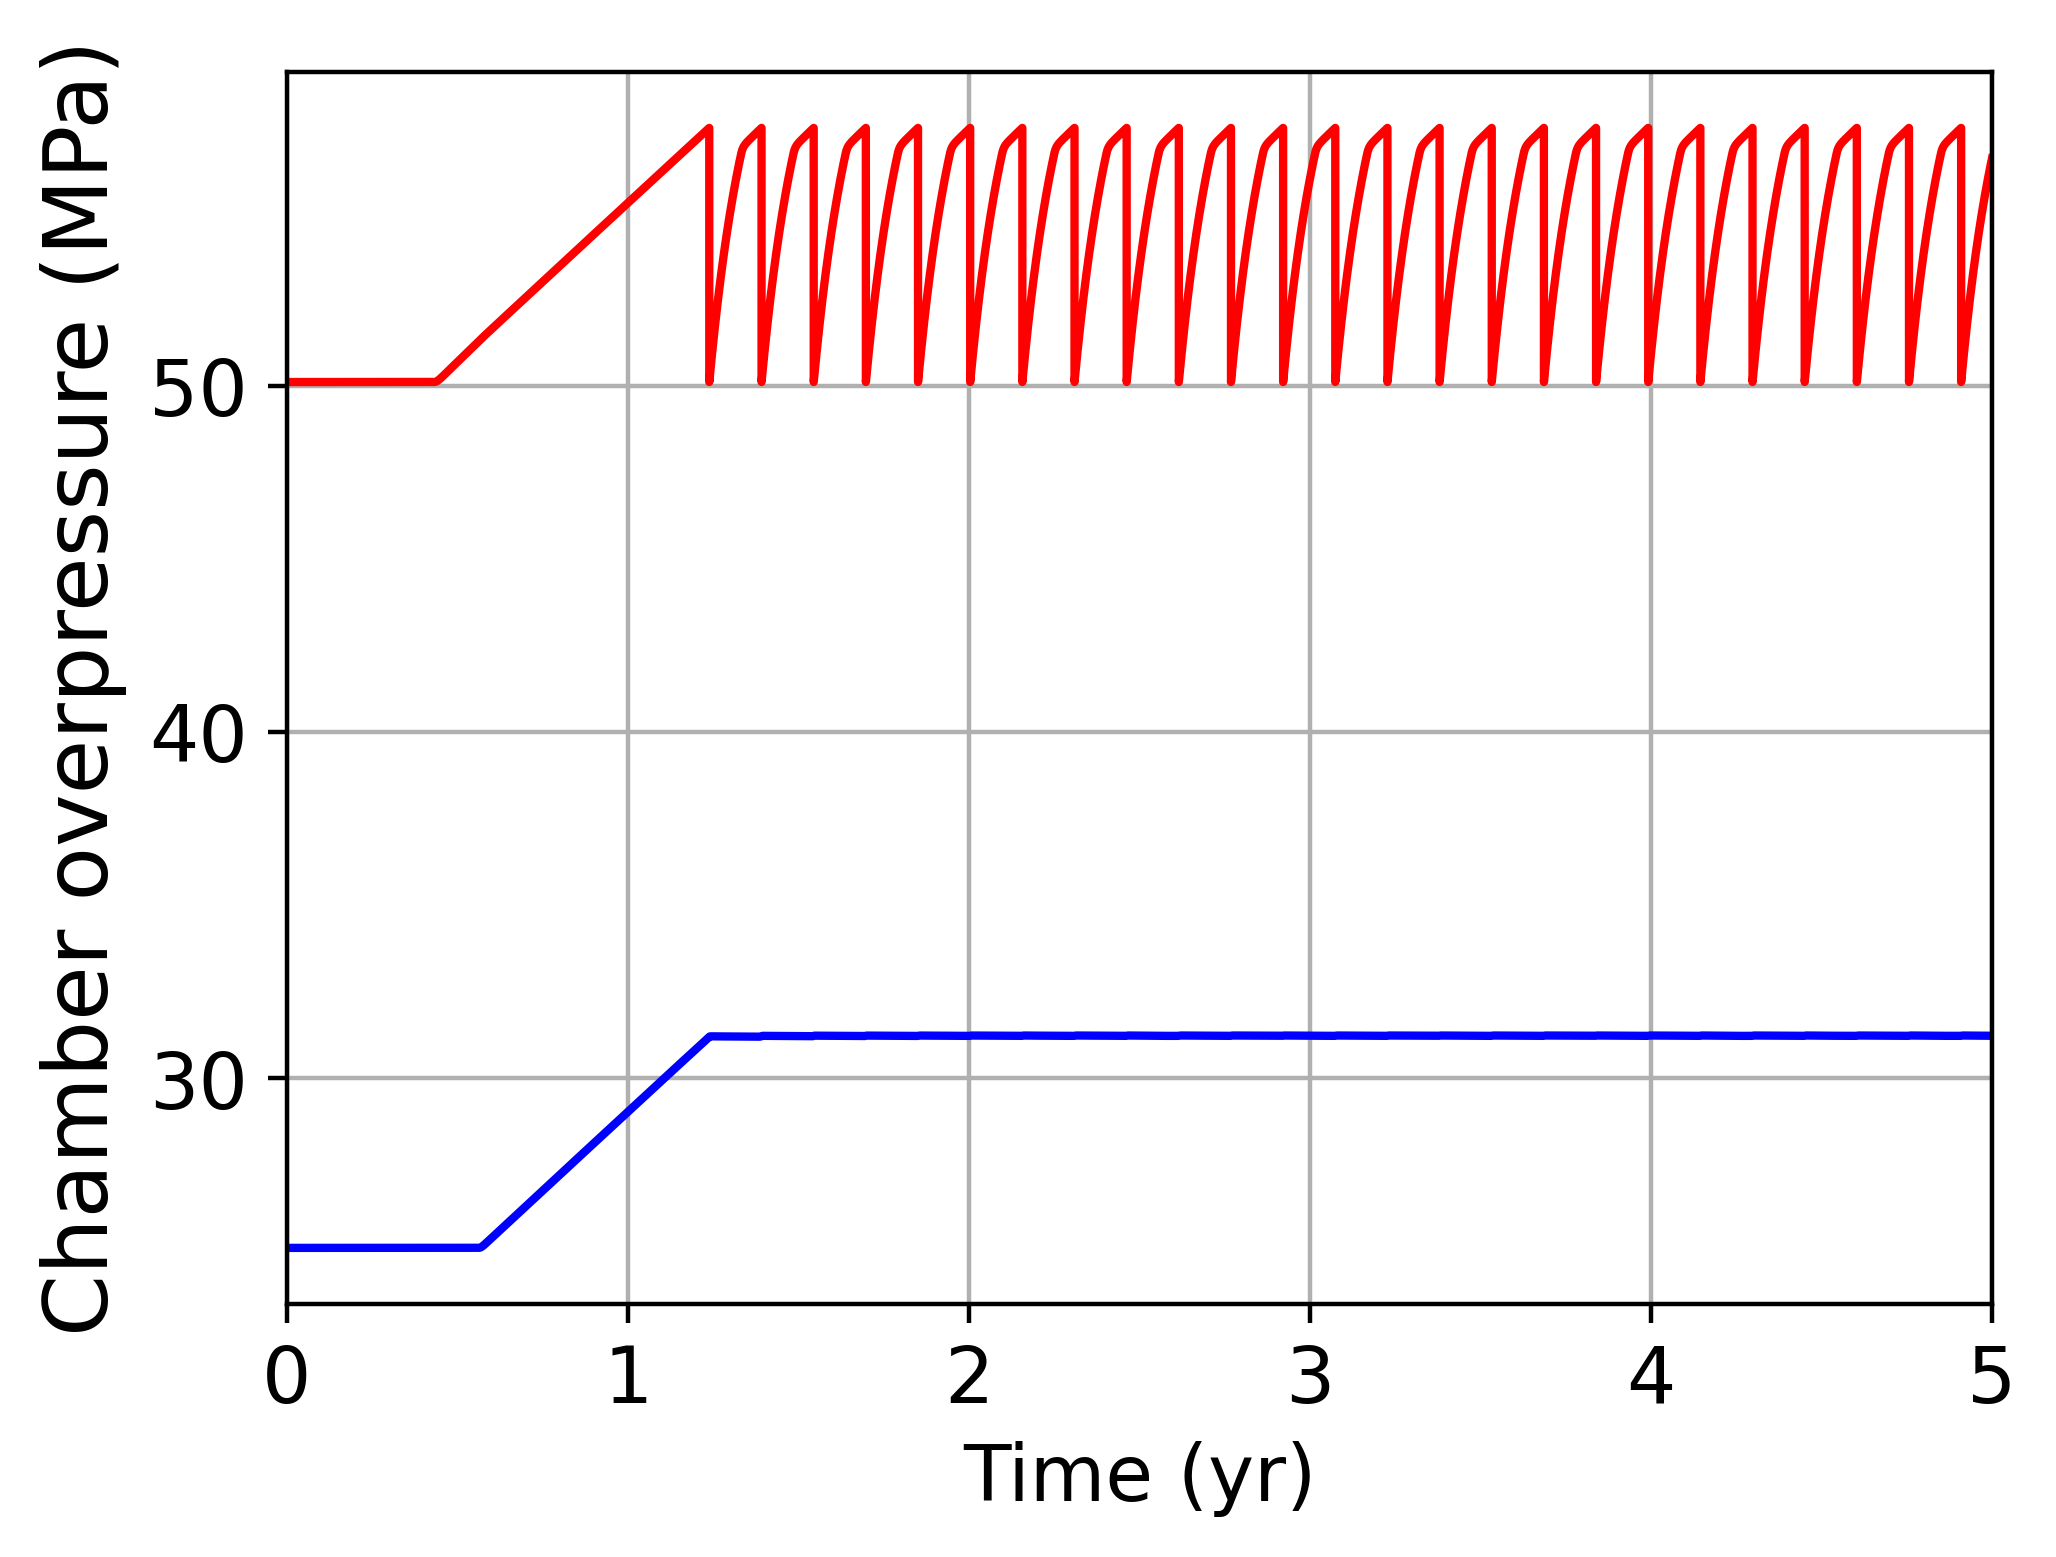

In [423]:
# Select a specific case
i, j = 18, 6
print("Crit. overpressure ratio: ", 1/mg_contrast[i,j])
print("Turnover rate (1/yr): ", mg_rates[i,j] * 3.1536e+7)

# plt.figure(figsize=(8,4))
plt.figure(figsize=(5.5,4), dpi=400)
# plt.subplot(1,2,1)
# plt.plot(t_vec, p[i,j][:,1])
# plt.subplot(1,2,2)
plt.plot(t_vec/ 3.1536e+7, (p[i,j][:,1] - 0*p[i,j][0,1]) / 1e6, 'b', linewidth=1.5)
plt.plot(t_vec/ 3.1536e+7, (p[i,j][:,2] - 0*p[i,j][0,2]) / 1e6, 'r', linewidth=1.5)
plt.tick_params(axis="both", labelsize=14)
plt.xlabel("Time (yr)", fontsize=14)
plt.xlim(0, 5)
plt.ylabel("Chamber overpressure (MPa)", fontsize=16)
plt.grid(which="both")
print("Pressure history for a specific case:")

### Convergence in $\Delta t$

In [4]:
props = cnetwork.default_props(
  t_d_default=1e9,
  t_b_default=1e13,
  r_hydr_default=100,
  )

def run_simulation(eruptibility_contrast, turnover_rate, ij, N_t=100000):
  # Set up fixed parameters
  ramp_time = 0.0
  p_erupt_min = 5e6
  t_vec = np.linspace(0, 20e7, N_t)

  global_sys = GlobalSystemThreshold(list_nodes,
    **props,
    **cnetwork.default_numerics(),
    dpdx_crit=1e3, dpdx_threshold_scale=1e2, max_edge_dist=np.inf,
    residual_overpressure=0,
    always_max_eruption_rate=True)
  
  def f_inj_ramp(t, q, max_rate=2e-11 * V_ref * rhoref,
               ramp_time=10e9, inject_node_idx=0):
    ''' Constant mass rate injection at node indices 0 and 1.
    Ramp function
    '''
    f_inj = np.zeros((global_sys.num_dof))
    if ramp_time == 0:
      mdot_inj = max_rate
    else:
      mdot_inj = max_rate * np.clip(t / ramp_time, 0.0, 1.0)

    f_inj[global_sys.data_slice_global(inject_node_idx, "mass")] = mdot_inj

    return f_inj

  # Set up varying parameters
  max_rate = turnover_rate * V_ref * rhoref
  f_erupt = global_sys.create_eruptible_layer(
    p_erupt_min=p_erupt_min,
    p_erupt_max=eruptibility_contrast*p_erupt_min,
    z_min=-2200, # global_sys.nodes[2].z,
    z_max=0.0, # global_sys.nodes[1].z,
    mu_erupt=1e5, r_conduit=25)
  
  # Run the simulation
  print(f"Simulation {ij} started.")
  q_out, m_erupted_out = global_sys.simulation(global_sys.q0, t_vec,
    lambda t, q: f_inj_ramp(t, q,
                            max_rate=max_rate,
                            ramp_time=ramp_time), f_erupt)
  
  # Post-process for dependent quantities
  m, p, u = global_sys.compute_m_p_u(q_out)
  m_eruption_by_chamber = np.array([
    -f_erupt(t_vec[i], q_out[i,:])[global_sys.mass_indices]
    for i, t in enumerate(t_vec)])

  print(f"Returning {ij}")

  return m_eruption_by_chamber, m, p, u

In [433]:
rate0, contrast0 = (4.666666666666667e-10, 1.0806451612903225)
4.666666666666667e-10 * seconds_per_year

0.014716800000000002

In [6]:
N_t_range = 4**np.arange(0, 8) * 200

# out format: m_eruption_by_chamber, m, p, u

outs = [run_simulation(1.0806451612903225,
               4.666666666666667e-10, N_t, N_t=N_t) for N_t in N_t_range] 

Simulation 200 started.
Returning 200
Simulation 800 started.
Returning 800
Simulation 3200 started.
Returning 3200
Simulation 12800 started.
Returning 12800
Simulation 51200 started.
Returning 51200
Simulation 204800 started.
Returning 204800
Simulation 819200 started.
Returning 819200
Simulation 3276800 started.
Returning 3276800


In [21]:
# m_eruption_by_chamber, m, p, u

np.savez_compressed(
  "fig_V_prod_dt_convergence.npz",
  all_m_eruption_by_chamber = [out[0] for out in outs],
  all_m = [out[1] for out in outs],
  all_p = [out[2] for out in outs],
  all_u = [out[3] for out in outs],
  N_t_range=N_t_range,
  all_t_vec = [np.linspace(0, 20e7, N_t) for N_t in N_t_range],)

c:\Python39\lib\site-packages\numpy\core\_asarray.py:171: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  return array(a, dtype, copy=False, order=order, subok=True)


Text(0, 0.5, 'Inter-eruption period (years)')

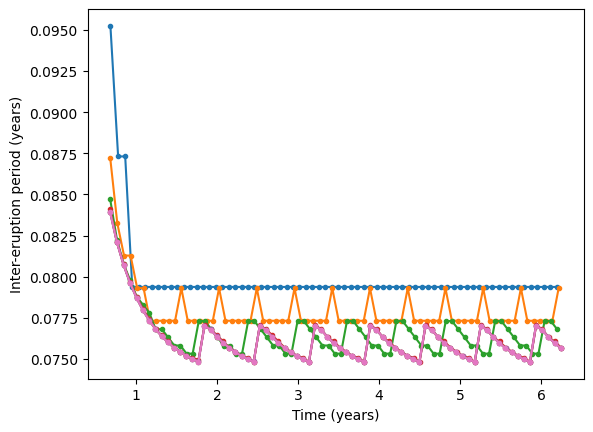

In [434]:
for i in range(1,8):
  N_t = N_t_range[i]
  t_vec = np.linspace(0, 20e7, N_t)

  seconds_per_year = 365 * 24 * 3600
  t_peak = pick_peaks(outs[i][0][:,2], t_vec)

  plt.plot(t_peak[:-1] / seconds_per_year, np.diff(t_peak) / seconds_per_year, '.-')
plt.xlabel("Time (years)")
plt.ylabel("Inter-eruption period (years)")

In [495]:
# Compute reference solution of IET
t1ref = pick_peaks(outs[-1][0][:,1], t_vec)[:-1] / seconds_per_year
t2ref = pick_peaks(outs[-1][0][:,2], t_vec)[:-1] / seconds_per_year
IET1ref = np.diff(pick_peaks(outs[-1][0][:,1], t_vec)) / seconds_per_year
IET2ref = np.diff(pick_peaks(outs[-1][0][:,2], t_vec)) / seconds_per_year

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript back

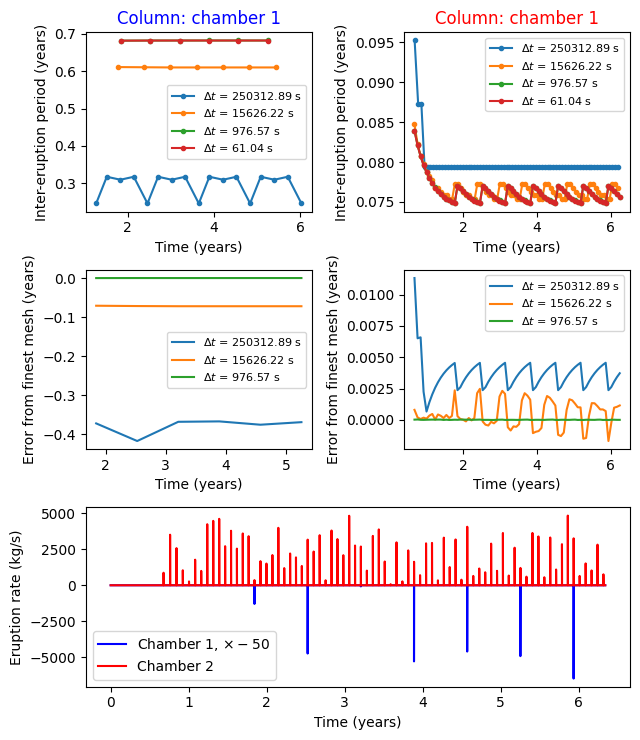

In [503]:
seconds_per_year = 365 * 24 * 3600

layout = [
    ['00', '01',],
    ['10', '11',],
    ['M', 'M',],
]

fig, ax = plt.subplot_mosaic(
  layout,
  figsize=(6.5, 7.5),
  gridspec_kw={
    'height_ratios': [1.0, 1.0, 1.0],
    # 'wspace': 0.65,
    # 'hspace': 0.4,
  },
  dpi=100,
)

for i in range(1,8,2):
  N_t = N_t_range[i]
  t_vec = np.linspace(0, 20e7, N_t)
  dt = t_vec[1] - t_vec[0]

  t_peak = pick_peaks(outs[i][0][:,1], t_vec)
  x = t_peak[:-1] / seconds_per_year
  y = np.diff(t_peak) / seconds_per_year
  ax["00"].plot(x, y, '.-', label=f"$\Delta t$ = {dt:.2f} s")
  if i < 7:
    ax["10"].plot(t1ref, np.interp(t1ref, x, y) - IET1ref, label=f"$\Delta t$ = {dt:.2f} s")

  t_peak = pick_peaks(outs[i][0][:,2], t_vec)
  x = t_peak[:-1] / seconds_per_year
  y = np.diff(t_peak) / seconds_per_year
  ax["01"].plot(x, y, '.-', label=f"$\Delta t$ = {dt:.2f} s")
  if i < 7:
    ax["11"].plot(t2ref, np.interp(t2ref, x, y) - IET2ref, label=f"$\Delta t$ = {dt:.2f} s")

ax["00"].set_xlabel("Time (years)")
ax["00"].set_ylabel("Inter-eruption period (years)")
ax["00"].legend(fontsize=8, loc="right")
ax["00"].set_title("Column: chamber 1", color="blue")

ax["10"].set_xlabel("Time (years)")
ax["10"].set_ylabel("Error from finest mesh (years)")
ax["10"].legend(fontsize=8, loc="right")

ax["01"].set_xlabel("Time (years)")
ax["01"].set_ylabel("Inter-eruption period (years)")
ax["01"].legend(fontsize=8, loc="upper right")
ax["01"].set_title("Column: chamber 1", color="red")

ax["11"].set_xlabel("Time (years)")
ax["11"].set_ylabel("Error from finest mesh (years)")
ax["11"].legend(fontsize=8, loc="upper right")

# Plot finest mesh solution, mass
# outs format: m_eruption_by_chamber, m, p, u
ax["M"].plot(t_vec / seconds_per_year, -50*outs[-1][0][:,1], 'b', label="Chamber 1, $\\times -50$")
ax["M"].plot(t_vec / seconds_per_year, outs[-1][0][:,2], 'r', label="Chamber 2")
ax["M"].set_xlabel("Time (years)")
ax["M"].set_ylabel("Eruption rate (kg/s)")
ax["M"].legend()

fig.tight_layout()
plt.savefig("fig_appendix_V_dt_convergence.png", dpi=200)
plt.savefig("fig_appendix_V_dt_convergence.eps")
plt.savefig("fig_appendix_V_dt_convergence.svg")